In [1]:

import pandas as pd

# Load the cleaned education dataset
df = pd.read_csv(
    "../outputs/fsm_primary_2025_26_clean.csv"
)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)

df.head()


Dataset loaded successfully!
Rows and columns: (152, 5)


,new_la_code,la_name,region_name,fsm_eligible_pupils,fsm_eligibility_percent
0,E08000003,Manchester,North West,24747,47.976968
1,E08000025,Birmingham,West Midlands,49541,47.056868
2,E09000019,Islington,London,5765,45.954564
3,E09000007,Camden,London,4451,45.376695
4,E09000012,Hackney,London,7207,43.290485


In [2]:
#Descriptive statistics for FSM eligibility
fsm_stats=df["fsm_eligibility_percent"].describe()
print(fsm_stats.round(2))

count    152.00
mean      25.48
std        8.25
min        9.40
25%       19.07
50%       24.73
75%       30.38
max       47.98
Name: fsm_eligibility_percent, dtype: float64


In [3]:


mean_fsm = df["fsm_eligibility_percent"].mean()
median_fsm = df["fsm_eligibility_percent"].median()

print(f"Mean FSM eligibility: {mean_fsm:.2f}%")
print(f"Median FSM eligibility: {median_fsm:.2f}%")


Mean FSM eligibility: 25.48%
Median FSM eligibility: 24.73%


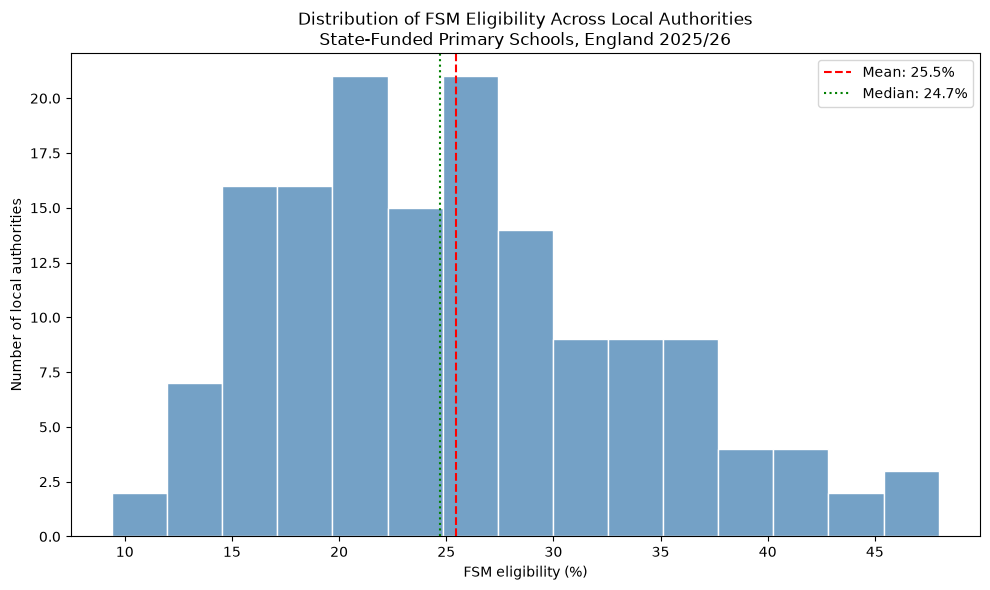

In [4]:

import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="fsm_eligibility_percent",
    bins=15,
    color="steelblue",
    edgecolor="white"
)

plt.axvline(
    mean_fsm,
    color="red",
    linestyle="--",
    label=f"Mean: {mean_fsm:.1f}%"
)

plt.axvline(
    median_fsm,
    color="green",
    linestyle=":",
    label=f"Median: {median_fsm:.1f}%"
)

plt.title(
    "Distribution of FSM Eligibility Across Local Authorities\n"
    "State-Funded Primary Schools, England 2025/26"
)

plt.xlabel("FSM eligibility (%)")
plt.ylabel("Number of local authorities")

plt.legend()
plt.tight_layout()
plt.show()


The distribution of FSM eligibility across 152 English local authorities shows considerable geographical variation. The mean eligibility rate was 25.48%, slightly higher than the median of 24.73%, suggesting a modest rightward asymmetry. Most local authorities were concentrated within the lower-to-middle percentage ranges, while fewer recorded particularly high eligibility rates. The standard deviation of 8.25 percentage points highlights variation between local authorities. These statistics represent an unweighted comparison of local authorities rather than the overall pupil eligibility rate in England.

In [5]:

# Explore the regions in our dataset

print(df["region_name"].unique())

print("\nLocal authorities per region:")
print(df["region_name"].value_counts())


<StringArray>
[              'North West',            'West Midlands',
                   'London',               'North East',
            'East Midlands',               'South East',
 'Yorkshire and The Humber',          'East of England',
               'South West']
Length: 9, dtype: str

Local authorities per region:
region_name
London                      33
North West                  24
South East                  19
Yorkshire and The Humber    15
West Midlands               14
South West                  14
North East                  12
East of England             11
East Midlands               10
Name: count, dtype: int64


In [6]:

# Calculate FSM statistics by region

regional_stats = (
    df.groupby("region_name")
    ["fsm_eligibility_percent"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

# Sort regions from highest to lowest mean
regional_stats = regional_stats.sort_values(
    "mean",
    ascending=False
)

regional_stats


,count,mean,median,min,max
region_name,,,,,
North East,12,31.07,29.28,22.08,41.94
West Midlands,14,28.27,25.20,17.48,47.06
North West,24,27.70,26.28,14.21,47.98
London,33,27.02,25.16,12.86,45.95
Yorkshire and The Humber,15,26.58,27.43,18.25,34.56
East Midlands,10,24.19,23.87,11.55,36.67
East of England,11,21.35,21.60,13.12,30.38
South East,19,20.77,21.11,9.40,36.05
South West,14,19.81,18.56,15.09,28.07


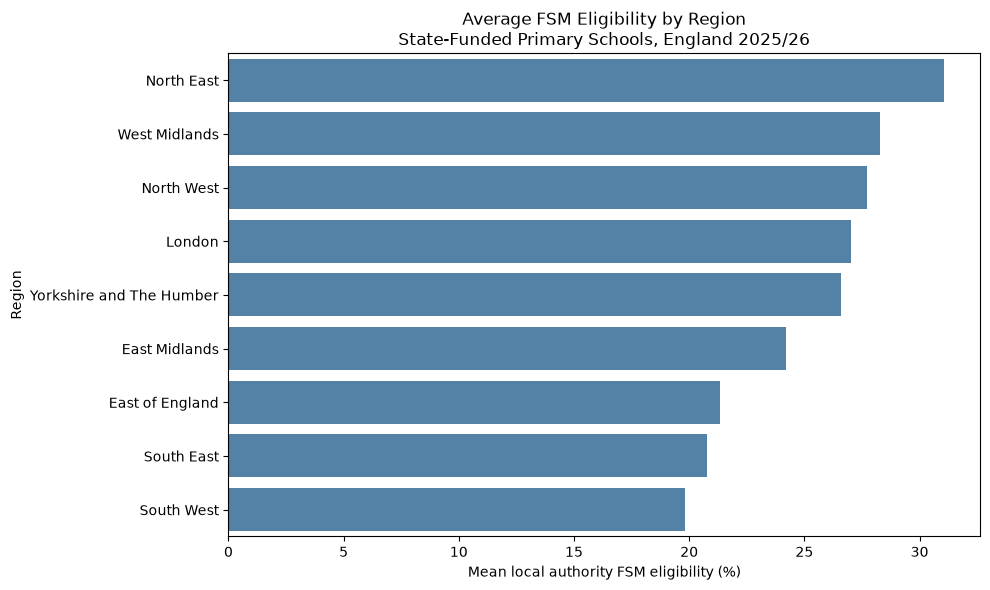

In [7]:

import matplotlib.pyplot as plt
import seaborn as sns

# Reset index so region names become a column
regional_plot = regional_stats.reset_index()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=regional_plot,
    x="mean",
    y="region_name",
    color="steelblue"
)

plt.title(
    "Average FSM Eligibility by Region\n"
    "State-Funded Primary Schools, England 2025/26"
)

plt.xlabel("Mean local authority FSM eligibility (%)")
plt.ylabel("Region")

plt.tight_layout()
plt.show()


In [8]:

from pathlib import Path
import pandas as pd

# Load original DfE data
csv_files = list(Path("../data").glob("*.csv"))

if len(csv_files) != 1:
    raise ValueError("Expected exactly one original CSV in data/")

raw = pd.read_csv(csv_files[0], low_memory=False)

# Select total primary-school pupils for each authority
df_total = raw[
    (raw["time_period"].astype(str) == "202526") &
    (raw["geographic_level"] == "Local authority") &
    (raw["phase_type_grouping"] == "State-funded primary") &
    (raw["fsm_eligibility"] == "Total") &
    (raw["fsm_breakdown"] == "All pupils")
][["new_la_code", "pupil_count"]].copy()

df_total = df_total.rename(
    columns={"pupil_count": "total_pupils"}
)

print("Total population records:", len(df_total))
print("Unique authorities:", df_total["new_la_code"].nunique())


Total population records: 152
Unique authorities: 152


In [9]:

# Merge using local authority codes
df_weighted = df.merge(
    df_total,
    on="new_la_code",
    how="left",
    validate="one_to_one"
)

# Calculate FSM percentage using pupil counts
df_weighted["calculated_fsm_percent"] = (
    df_weighted["fsm_eligible_pupils"] /
    df_weighted["total_pupils"]
) * 100

# Check our calculations
print("Missing total pupil counts:",
      df_weighted["total_pupils"].isna().sum())

print("Non-positive pupil totals:",
      (df_weighted["total_pupils"] <= 0).sum())

print("Largest difference from published FSM percentage:",
      (
          df_weighted["calculated_fsm_percent"] -
          df_weighted["fsm_eligibility_percent"]
      ).abs().max())

df_weighted.head()


Missing total pupil counts: 0
Non-positive pupil totals: 0
Largest difference from published FSM percentage: 4.973799150320701e-14


,new_la_code,la_name,region_name,fsm_eligible_pupils,fsm_eligibility_percent,total_pupils,calculated_fsm_percent
0,E08000003,Manchester,North West,24747,47.976968,51581,47.976968
1,E08000025,Birmingham,West Midlands,49541,47.056868,105279,47.056868
2,E09000019,Islington,London,5765,45.954564,12545,45.954564
3,E09000007,Camden,London,4451,45.376695,9809,45.376695
4,E09000012,Hackney,London,7207,43.290485,16648,43.290485


In [10]:

# Add up eligible pupils and total pupils by region
regional_weighted = df_weighted.groupby(
    "region_name"
)[["fsm_eligible_pupils", "total_pupils"]].sum()

# Calculate regional FSM rates
regional_weighted["weighted_fsm_percent"] = (
    regional_weighted["fsm_eligible_pupils"] /
    regional_weighted["total_pupils"]
) * 100

# Add our previous unweighted regional means
regional_weighted["unweighted_mean"] = (
    df.groupby("region_name")[
        "fsm_eligibility_percent"
    ].mean()
)

# Compare the results
regional_weighted[
    ["unweighted_mean", "weighted_fsm_percent"]
].round(2).sort_values(
    "weighted_fsm_percent",
    ascending=False
)


,unweighted_mean,weighted_fsm_percent
region_name,,
North East,31.07,31.12
West Midlands,28.27,30.39
North West,27.70,28.02
Yorkshire and The Humber,26.58,26.61
London,27.02,26.10
East Midlands,24.19,24.75
South East,20.77,20.37
East of England,21.35,20.14
South West,19.81,19.80


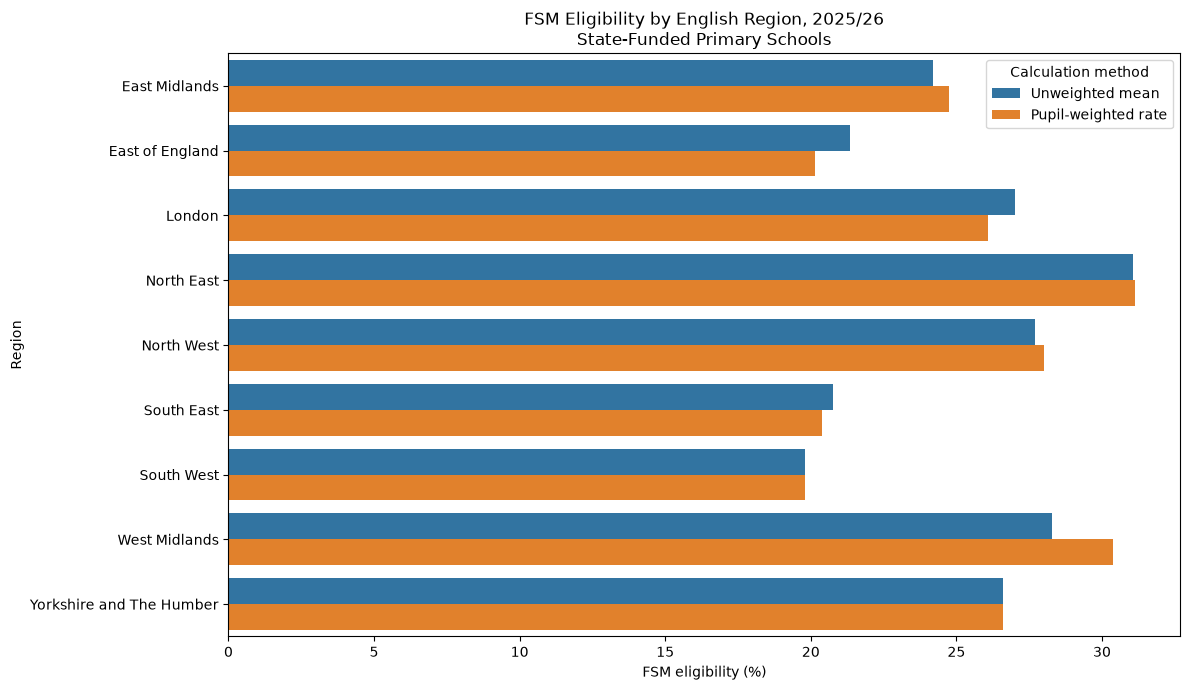

In [11]:

import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for visualisation
chart_data = regional_weighted[
    ["unweighted_mean", "weighted_fsm_percent"]
].reset_index()

chart_data = chart_data.melt(
    id_vars="region_name",
    var_name="Method",
    value_name="FSM percentage"
)

chart_data["Method"] = chart_data["Method"].replace({
    "unweighted_mean": "Unweighted mean",
    "weighted_fsm_percent": "Pupil-weighted rate"
})

# Create chart
fig, ax = plt.subplots(figsize=(12, 7))

sns.barplot(
    data=chart_data,
    x="FSM percentage",
    y="region_name",
    hue="Method",
    ax=ax
)

ax.set_title(
    "FSM Eligibility by English Region, 2025/26\n"
    "State-Funded Primary Schools"
)

ax.set_xlabel("FSM eligibility (%)")
ax.set_ylabel("Region")
ax.legend(title="Calculation method")

plt.tight_layout()

# Save to the GitHub project's outputs folder
fig.savefig(
    "../outputs/regional_fsm_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


The analysis revealed geographical variation in FSM eligibility across nine English regions. The North East recorded the highest pupil-weighted eligibility rate (31.12%), while the South West recorded the lowest (19.80%). Although weighted and unweighted measures were relatively similar in several regions, the West Midlands showed a difference of 2.12 percentage points. This demonstrates that differences in local authority pupil populations can influence regional estimates. Pupil-weighted rates are more appropriate when estimating the proportion of pupils eligible for FSM across an entire region.

In [12]:

# Compare calculated and published percentages
df_weighted["percentage_difference"] = (
    df_weighted["calculated_fsm_percent"]
    - df_weighted["fsm_eligibility_percent"]
).abs()

print("Largest difference:")
print(df_weighted["percentage_difference"].max())

print("\nRecords with differences above 0.01 percentage points:")
print(
    (df_weighted["percentage_difference"] > 0.01).sum()
)


Largest difference:
4.973799150320701e-14

Records with differences above 0.01 percentage points:
0


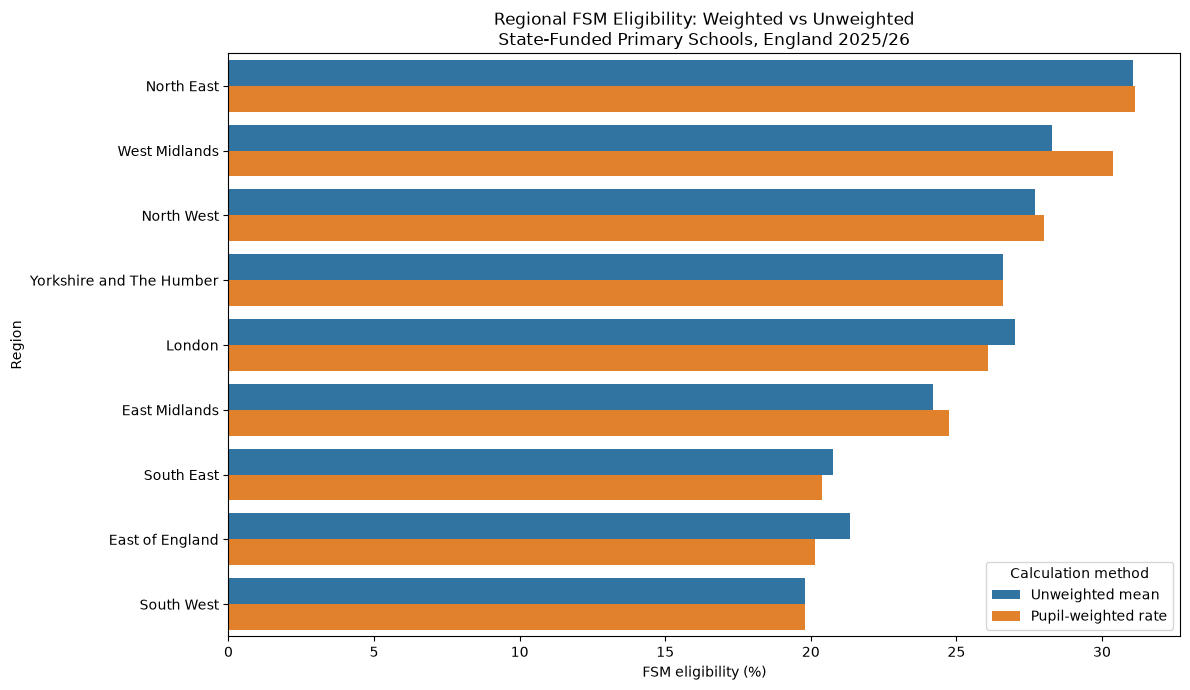

In [13]:

import matplotlib.pyplot as plt
import seaborn as sns

# Rank regions by their weighted FSM percentage
region_order = (
    regional_weighted
    .sort_values("weighted_fsm_percent", ascending=False)
    .index.tolist()
)

fig, ax = plt.subplots(figsize=(12, 7))

sns.barplot(
    data=chart_data,
    x="FSM percentage",
    y="region_name",
    hue="Method",
    order=region_order,
    ax=ax
)

ax.set_title(
    "Regional FSM Eligibility: Weighted vs Unweighted\n"
    "State-Funded Primary Schools, England 2025/26"
)

ax.set_xlabel("FSM eligibility (%)")
ax.set_ylabel("Region")

ax.legend(title="Calculation method")

plt.tight_layout()

fig.savefig(
    "../outputs/regional_fsm_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [14]:

# Select West Midlands local authorities

west_midlands = df_weighted[
    df_weighted["region_name"] == "West Midlands"
].copy()

# Sort by total primary pupil population
west_midlands = west_midlands.sort_values(
    "total_pupils",
    ascending=False
)

# Display relevant columns
west_midlands[
    [
        "la_name",
        "total_pupils",
        "fsm_eligible_pupils",
        "fsm_eligibility_percent"
    ]
]


,la_name,total_pupils,fsm_eligible_pupils,fsm_eligibility_percent
1,Birmingham,105279,49541,47.056868
113,Staffordshire,66301,12736,19.209363
96,Warwickshire,47645,10290,21.597230
118,Worcestershire,40911,7581,18.530469
25,Sandwell,35533,12266,34.520024
66,Coventry,33222,8408,25.308530
21,Walsall,28451,10065,35.376612
73,Dudley,27643,6937,25.094961
5,Wolverhampton,26285,11093,42.202777
7,Stoke-on-Trent,24289,10087,41.529087


In [15]:

from pathlib import Path

output_folder = Path("../outputs")
output_folder.mkdir(exist_ok=True)

# Save the regional statistics
regional_weighted.to_csv(
    output_folder / "regional_fsm_statistics_2025_26.csv"
)

print("Regional statistics saved successfully!")


Regional statistics saved successfully!


Finding 2: Regional differences in FSM eligibility

The North East had the highest pupil-weighted FSM eligibility rate (31.12%), while the South West had the lowest (19.80%).

Although weighted and unweighted regional measures were similar in several regions, the West Midlands showed a difference of 2.12 percentage points.

Further investigation found that Birmingham had 105,279 primary school pupils and an FSM eligibility rate of 47.06%. Its relatively large pupil population and high eligibility rate help explain the difference between the two regional measures.

Recalculating the eligibility percentages from pupil counts produced results consistent with the published data.